## Set up

In [4]:
# set scripts

import subprocess
import sys
from pathlib import Path


ROOT = Path.cwd().resolve()

def run_script(module_name):
    subprocess.run(
        [
            sys.executable,
            "-m",
            f"scripts.{module_name}"
        ],
        cwd=ROOT,
        check=True
    )

print("Project root:", ROOT)
print("Python executable:", sys.executable)

Project root: /data/zichunhsu/SGLT2_github
Python executable: /opt/anaconda3/bin/python


In [2]:
# check packages

import csv
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pickle
import requests
import shap
import tqdm
from scipy.stats import hypergeom, combine_pvalues
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

from src.features import select_features
from src.training import train_model_repeated_stratified_rf

print("All imports successful")

All imports successful


## Training and prediction

In [ ]:
run_script("compare_feature_sets")

In [3]:
run_script("compare_models")


===== first: XGBoost =====
Loading data...
Feature set       : 1048
Selected features : 1048
Number of samples  : 2740
Number of features : 1048

Class distribution:
label
1    1370
0    1370
Name: count, dtype: int64

Cross-validation strategy: Repeated Stratified 5-Fold × 10 repeats
Total model evaluations: 50

Training model 1/50 (Repeat 1/10, Fold 1/5)...
  Training class distribution: negative=1096, positive=1096, scale_pos_weight=1.0000
Training model 2/50 (Repeat 1/10, Fold 2/5)...
  Training class distribution: negative=1096, positive=1096, scale_pos_weight=1.0000
Training model 3/50 (Repeat 1/10, Fold 3/5)...
  Training class distribution: negative=1096, positive=1096, scale_pos_weight=1.0000
Training model 4/50 (Repeat 1/10, Fold 4/5)...
  Training class distribution: negative=1096, positive=1096, scale_pos_weight=1.0000
Training model 5/50 (Repeat 1/10, Fold 5/5)...
  Training class distribution: negative=1096, positive=1096, scale_pos_weight=1.0000
Training model 6/50 (Rep

/data/zichunhsu/SGLT2_github/src/training.py:1257: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_results[probability_column] = -1.0
/data/zichunhsu/SGLT2_github/src/training.py:1266: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_results[prediction_column] = -1



Repeated Stratified K-Fold XGBoost completed!
Number of folds     : 5
Number of repeats   : 10
Total evaluations   : 50

Performance summary:
           Metric     Mean      Std
      sensitivity 0.998832 0.001991
      specificity 0.997299 0.003779
        precision 0.997318 0.003721
         accuracy 0.998066 0.002013
              mcc 0.996143 0.004000
average_precision 0.999937 0.000122
          roc_auc 0.999932 0.000135

Sample test frequency:
test_times
10    2740
Name: count, dtype: int64

Training and evaluation completed!

===== second: XGBoost =====
Loading data...
Feature set       : 1048
Selected features : 1048
Number of samples  : 1119
Number of features : 1048

Class distribution:
label
1    667
0    452
Name: count, dtype: int64

Cross-validation strategy: Repeated Stratified 5-Fold × 10 repeats
Total model evaluations: 50

Training model 1/50 (Repeat 1/10, Fold 1/5)...
  Training class distribution: negative=362, positive=533, scale_pos_weight=0.6792
Training model 2

/data/zichunhsu/SGLT2_github/src/training.py:1257: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_results[probability_column] = -1.0
/data/zichunhsu/SGLT2_github/src/training.py:1266: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_results[prediction_column] = -1



Repeated Stratified K-Fold XGBoost completed!
Number of folds     : 5
Number of repeats   : 10
Total evaluations   : 50

Performance summary:
           Metric     Mean      Std
      sensitivity 0.917082 0.025518
      specificity 0.853121 0.035253
        precision 0.902576 0.021177
         accuracy 0.891242 0.019421
              mcc 0.774275 0.040404
average_precision 0.959245 0.011666
          roc_auc 0.948227 0.012735

Sample test frequency:
test_times
10    1119
Name: count, dtype: int64

Training and evaluation completed!


In [ ]:
run_script("train_final_models")

In [ ]:
run_script("screen_pdb")

## Data processing and analysis

In [22]:
# check features

import pandas as pd
from src.features import select_features

for stage in ["first", "second"]:
    data = pd.read_csv(
        f"./data/{stage}_1048.txt",
        sep="\t",
        index_col=0
    )

    X = data.iloc[:, 1:]

    for feature_set in ["1048", "ecfp", "moiety", "numeric"]:
        selected = select_features(X, feature_set)
        print(stage, feature_set, selected.shape, "\n")

Feature set       : 1048
Selected features : 1048
first 1048 (2740, 1048) 

Feature set       : ecfp
Selected features : 512
first ecfp (2740, 512) 

Feature set       : moiety
Selected features : 519
first moiety (2740, 519) 

Feature set       : numeric
Selected features : 17
first numeric (2740, 17) 

Feature set       : 1048
Selected features : 1048
second 1048 (1119, 1048) 

Feature set       : ecfp
Selected features : 512
second ecfp (1119, 512) 

Feature set       : moiety
Selected features : 519
second moiety (1119, 519) 

Feature set       : numeric
Selected features : 17
second numeric (1119, 17) 



In [ ]:
# calculate pairing proteins and pairs using given ligand list 

run_script("get_ligands_proteins_pairs_number")

./data/pdb_ligand_first_passed.txt, num of liands = 717
read ./data/pdb_ligand_uniprot_map.json ...


num of ligands from input file  : 717
num of ligands found in JSON    : 681
num of ligands not found in JSON: 36
------------------------------------------
num of unique proteins          : 4,033
num of unique pairs             : 8,194
------------------------------------------
data saved as                   : ./data/pdb_ligand_first_passed_matched_ligand_uniprot_pairs.csv


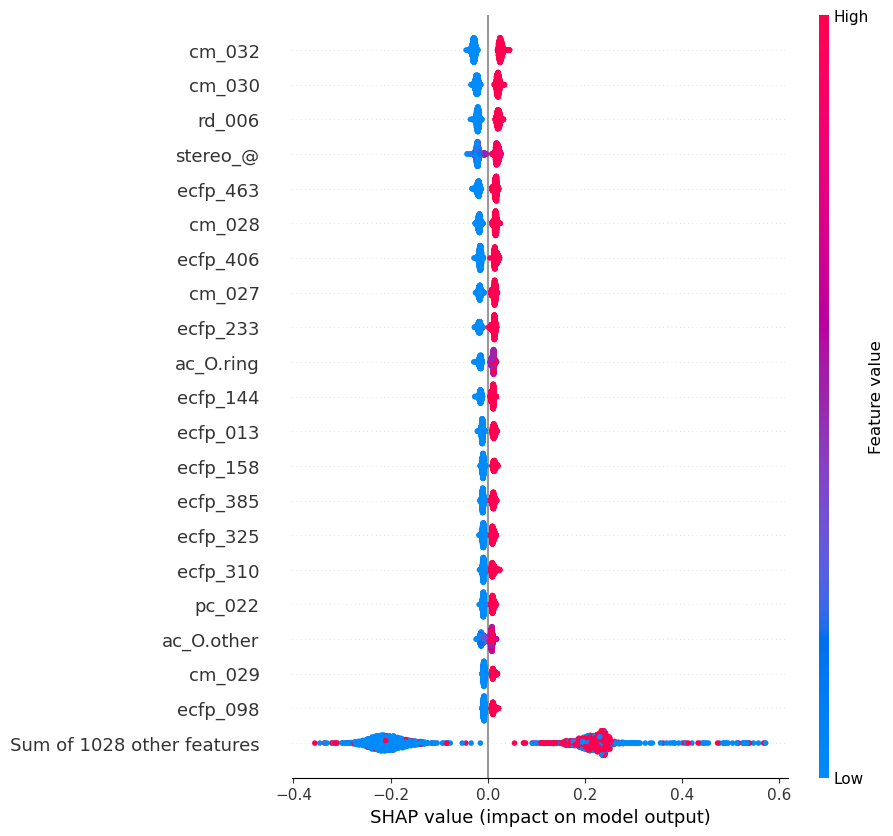

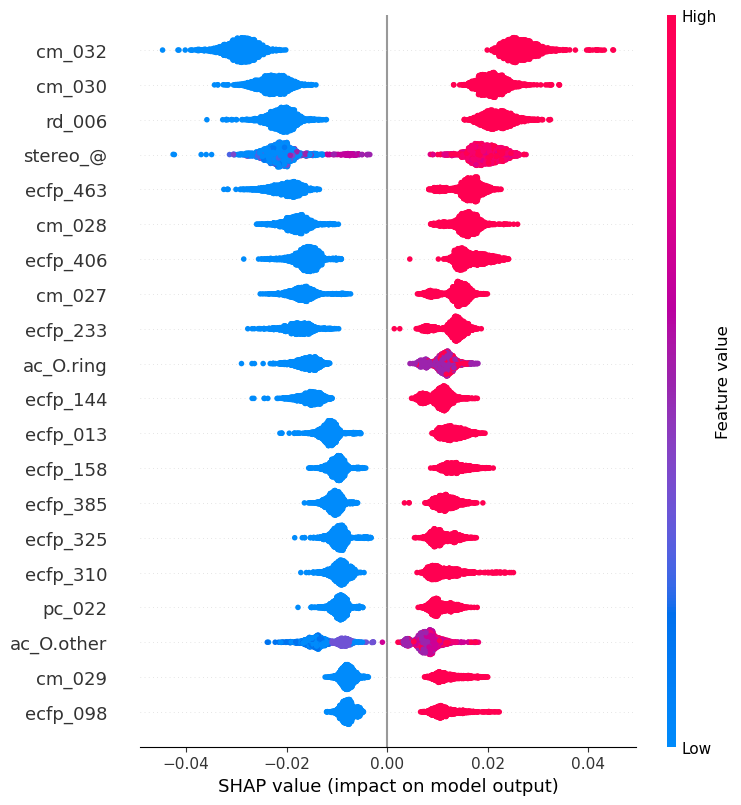

In [ ]:
# draw SHAP beeswarm plot

from src.interpretation import draw_shap
draw_shap(
    input_dataset_path="./data/first_1048.txt",
    out_of_fold_shap_mean_path=(
        "./results/rf_first_1048/"
        "out_of_fold_SHAP_mean.csv"
    ),
    max_display_num=21
)

from src.interpretation import draw_shap
draw_shap(
    input_dataset_path="./data/second_1048.txt",
    out_of_fold_shap_mean_path=(
        "./results/rf_second_1048/"
        "out_of_fold_SHAP_mean.csv"
    ),
    max_display_num=21
)

In [ ]:
# perform hypergeom test

run_script("analyze_sglt2_aa_enrichment")

Analysis completed.
Per-structure results: ./results/sglt2_aa_enrichment/SGLT2_AA_enrichment_per_structure.csv
Combined + FDR results: ./results/sglt2_aa_enrichment/SGLT2_AA_enrichment_combined_FDR.csv
Heatmap matrix: ./results/sglt2_aa_enrichment/SGLT2_AA_enrichment_heatmap.csv


## Compound features

In [42]:
%load_ext autoreload
%autoreload 2

from src.features import (
    mol_to_ecfp,
    mol_to_checkmol,
    mol_to_pubchem,
    mol_to_ringsindrugs,
    mol_to_ac,
    mol_to_stereo,
    mol_to_smiles,
    smiles_to_stereo,
    smiles_to_temp_mol
    )

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
print(mol_to_stereo(smiles_to_temp_mol('CCc1ccc(Cc2ccc3CO[C@]4(O[C@H](CO)[C@@H](O)[C@H](O)[C@@H]4O)c3c2)cc1')))

@, \, /, continue_@, continue_@@, first_@, first_@@
[7, 0, 0, 2, 0, 1, 0]
